Starting Batch Harvest...
D = 0.0 | Mean TET = 33.42s ± 0.32s
D = 0.1 | Mean TET = 35.17s ± 0.58s
D = 0.2 | Mean TET = 35.84s ± 0.44s
D = 0.3 | Mean TET = 36.84s ± 0.47s
D = 0.4 | Mean TET = 37.16s ± 0.59s
D = 0.5 | Mean TET = 37.39s ± 0.60s
D = 0.6 | Mean TET = 37.14s ± 0.90s
D = 0.7 | Mean TET = 37.21s ± 0.44s
D = 0.8 | Mean TET = 37.44s ± 0.58s
D = 0.9 | Mean TET = 37.19s ± 1.02s
D = 1.0 | Mean TET = 36.18s ± 0.80s
D = 1.1 | Mean TET = 36.73s ± 0.65s
D = 1.2 | Mean TET = 36.62s ± 1.13s
D = 1.3 | Mean TET = 35.41s ± 0.66s
D = 1.4 | Mean TET = 36.18s ± 1.14s
D = 1.5 | Mean TET = 34.72s ± 0.75s
D = 1.6 | Mean TET = 35.04s ± 0.92s
D = 1.7 | Mean TET = 35.07s ± 0.85s
D = 1.8 | Mean TET = 35.11s ± 1.10s
D = 1.9 | Mean TET = 34.39s ± 0.96s
D = 2.0 | Mean TET = 33.65s ± 0.52s


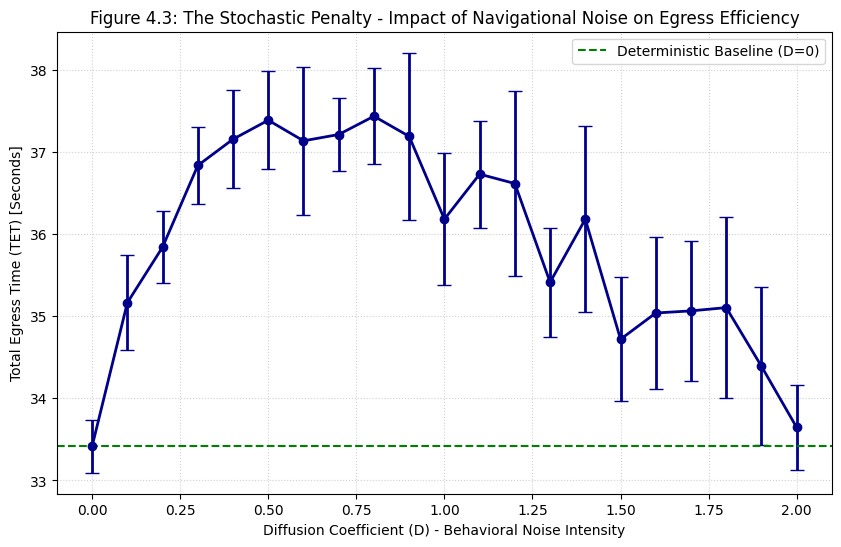

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import matplotlib as mpl

# COMPONENT 1 - Simulation Constants & Parameters

dt = 0.02             
n_agents = 50        
m = 70.0              
tau = 0.5             
v0_desired = 1.34     

# EXPERIMENTAL VARIABLES (Only change these for your results)
D_val = 2.5           # Scenario Noise
vomitory_width = 2.0  # Bottleneck Width

# HEURISTIC CALIBRATION CONSTANTS (Fixed for all runs to ensure stability)
# Wall Physics
k_wall = 7500.0      # High stiffness for concrete boundaries
buffer_wall = 0.25     # Low buffer for hard walls
c_wall_damp = 1000.0  # Damping to prevent bouncing off walls

# Social Physics
k_soc = 5000.0        # Stiff social repulsion for "Granular" behavior
buffer_soc = 1.0      # Realistic human buffer zone
c_soc_damp = 750.0    # Social damping to facilitate clogging/freezing
agent_radius = 0.25   

# Force and Velocity Caps
cap_drive = 1000.0    # Calibrated to allow social stalling
cap_bound = 5000.0    # High to prevent clipping
cap_soc = 3500.0      # Allows social force to win over intent
v_cap = 3.0           

# Geometry Setup
x_spawn_line, x_funnel_start, x_bottleneck, exit_target_x = -10.0, -10.0, 0.0, 12.0
y_corridor_low = 5.0 - (vomitory_width/2)
y_corridor_high = 5.0 + (vomitory_width/2)
stadium_opening_width = 6.0 
y_stadium_low, y_stadium_high = 2.0, 8.0
slope_top = (y_corridor_high - y_stadium_high) / (x_bottleneck - x_funnel_start)
slope_bot = (y_corridor_low - y_stadium_low) / (x_bottleneck - x_funnel_start)

# COMPONENT 2 - Initialising Agents

# "Pulse" spawning to trigger immediate clog
entry_delay = 0.05     
entry_times = np.arange(n_agents) * entry_delay

# Agent Heterogeneity (Noise and Mass slightly varied to break symmetry)
D_agents = np.maximum(0, np.full(n_agents, D_val) + np.random.uniform(-0.01, 0.01, n_agents))
# Small mass variation is common in engineering to break mathematical deadlocks
m_agents = np.full(n_agents, m) + np.random.uniform(-2, 2, n_agents)

# Start positions: Vertical spread across the ENTIRE WIDE opening at x=-10
pos = np.zeros((n_agents, 2))
pos[:, 0] = x_spawn_line      
pos[:, 1] = np.linspace(y_stadium_low + 0.5, y_stadium_high - 0.5, n_agents)

vel = np.zeros((n_agents, 2))
exited_mask = np.zeros(n_agents, dtype=bool)

# The "Brain" Lists - Initializing empty lists to store time-series data
history_pos = []      # Stores [x, y] coordinates for every agent
history_vel = []      # Stores [vx, vy] vectors (needed for speed-based coloring)
history_density = []  # Stores a single integer (count of agents in Danger Zone)

# Function to calculate wall height based on current x-coordinate
def get_wall_heights(x):
    """Calculates y_low and y_high at a given x for funnel geometry."""
    y_high = np.piecewise(x, [x < x_bottleneck, x >= x_bottleneck], 
                          [lambda x: y_stadium_high + slope_top*(x - x_funnel_start), 
                           y_corridor_high])
    y_low = np.piecewise(x, [x < x_bottleneck, x >= x_bottleneck], 
                         [lambda x: y_stadium_low + slope_bot*(x - x_funnel_start), 
                          y_corridor_low])
    return y_low, y_high


# COMPONENT 3 - Simulation Loop

# STEP 4 & 5: THE DATA HARVEST ENGINE

def run_science_test(D_test_val, initial_pos, initial_vel):
    """
    Runs a single simulation and returns the exact TET.
    """
    # 1. Local Setup
    t_pos = initial_pos.copy()
    t_vel = initial_vel.copy()
    t_exited_mask = np.zeros(n_agents, dtype=bool)
    
    # 2. Fix the D=0 Crash: np.maximum(0, ...) ensures we never sqrt a negative
    D_agents_batch = np.maximum(0, np.full(n_agents, D_test_val) + np.random.uniform(-0.01, 0.01, n_agents))

    # 3. Increase limit to ensure slow clogs finish (120 seconds)
    max_steps = 15000 
    
    for step in range(max_steps):
        t = step * dt
        active_mask = t >= entry_times
        t_exited_mask[t_pos[:, 0] >= exit_target_x] = True
        in_sim_mask = active_mask & ~t_exited_mask
        
        # Check if EVERYONE has crossed x=12
        if np.all(t_exited_mask):
            return step * dt
        
        if not np.any(in_sim_mask): continue

        # 1a - Drive
        f_drive = np.zeros_like(t_pos)
        e_i = np.zeros_like(t_pos)
        funnel_z = (t_pos[:, 0] < x_bottleneck) & in_sim_mask
        corr_z = (t_pos[:, 0] >= x_bottleneck) & in_sim_mask
        target_f = np.array([x_bottleneck, 5.0])
        diff_f = target_f - t_pos[funnel_z]
        e_i[funnel_z] = diff_f / (np.linalg.norm(diff_f, axis=1, keepdims=True) + 1e-6)
        e_i[corr_z] = np.array([1.0, 0.0])
        f_drive[in_sim_mask] = m * (v0_desired * e_i[in_sim_mask] - t_vel[in_sim_mask]) / tau
        
        # 1b - Walls (Quadratic Non-Sucking Repulsion)
        f_bound = np.zeros_like(t_pos)
        for i in np.where(in_sim_mask)[0]:
            y_l, y_h = get_wall_heights(t_pos[i, 0])
            dist_h, dist_l = y_h - t_pos[i, 1], t_pos[i, 1] - y_l
            if dist_h < buffer_wall: f_bound[i] += k_wall * (buffer_wall - dist_h)**2 * np.array([0, -1])
            if dist_l < buffer_wall: f_bound[i] += k_wall * (buffer_wall - dist_l)**2 * np.array([0, 1])

        # 1c - Social (Anisotropy & Back-pressure)
        f_soc = np.zeros_like(t_pos)
        idx = np.where(in_sim_mask)[0]
        for i in idx:
            others = [j for j in idx if j != i]
            if not others: continue
            diff = t_pos[i] - t_pos[others]; dist = np.linalg.norm(diff, axis=1, keepdims=True)
            overlap = np.maximum(0, buffer_soc - dist)
            n_ij = diff / (dist + 1e-6)
            cos_phi = np.sum(-n_ij * (t_vel[i] / (np.linalg.norm(t_vel[i]) + 1e-6)), axis=1, keepdims=True)
            w_ij = np.where(cos_phi >= 0, 1.0, 0.5) 
            f_soc[i] = np.sum(w_ij * (k_soc * overlap * n_ij), axis=0)

        # 1d - Hierarchy Capping
        def cap(f, val):
            mag = np.linalg.norm(f, axis=1, keepdims=True)
            return np.where(mag > val, f * (val / (mag + 1e-9)), f)
        f_drive, f_bound, f_soc = cap(f_drive, cap_drive), cap(f_bound, cap_bound), cap(f_soc, cap_soc)

        # 2 & 3 - Updates & No-Moonwalk Filter
        noise = np.sqrt(2 * D_agents_batch[in_sim_mask, np.newaxis]) * np.random.normal(0, 1, (np.sum(in_sim_mask), 2))
        t_vel[in_sim_mask] += ((f_drive + f_bound + f_soc)[in_sim_mask] / m) * dt + noise * np.sqrt(dt)
        t_vel[in_sim_mask, 0] = np.maximum(0, t_vel[in_sim_mask, 0]) # THE BRAKE
        t_pos[in_sim_mask] += t_vel[in_sim_mask] * dt
        
        # 4 - Wall Clamp
        y_min, y_max = get_wall_heights(t_pos[in_sim_mask, 0])
        t_pos[in_sim_mask, 1] = np.clip(t_pos[in_sim_mask, 1], y_min + agent_radius, y_max - agent_radius)

    return max_steps * dt # Returns 120s if they timed out

# THE DATA HARVEST LOOP

D_target_vals = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2.0]
results_tet = []
results_std = []

print("Starting Batch Harvest...")

n_repeats = 7  # odd number, good balance of speed vs confidence

for d in D_target_vals:
    repeat_tets = []
    for _ in range(n_repeats):
        repeat_tets.append(run_science_test(d, pos, vel))
    results_tet.append(np.mean(repeat_tets))
    results_std.append(np.std(repeat_tets))
    print(f"D = {d} | Mean TET = {np.mean(repeat_tets):.2f}s ± {np.std(repeat_tets):.2f}s")

# GENERATING Figure 4.3)

plt.figure(figsize=(10, 6))
plt.errorbar(D_target_vals, results_tet, yerr=results_std, marker='o', linestyle='-', color='darkblue', linewidth=2, capsize=5)
plt.axhline(y=results_tet[0], color='green', linestyle='--', label='Deterministic Baseline (D=0)')

plt.title("Figure 4.3: The Stochastic Penalty - Impact of Navigational Noise on Egress Efficiency")
plt.xlabel("Diffusion Coefficient (D) - Behavioral Noise Intensity")
plt.ylabel("Total Egress Time (TET) [Seconds]")
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.show()

In [18]:
# Component 5.4 - Speed-Based Animation (Jupyter Render)
# Uses FuncAnimation to visualize frame-by-frame arching

# Pre-convert lists to numpy arrays for faster animation indexing
history_pos = np.array(history_pos)
history_vel = np.array(history_vel)

fig, ax = plt.subplots(figsize=(12, 6))

# Draw the Funnel Boundaries (Static in the animation)
walls_x_ani = np.linspace(-12, exit_target_x + 2, 500)
walls_y_low_ani, walls_y_high_ani = get_wall_heights(walls_x_ani)
ax.plot(walls_x_ani, walls_y_high_ani, color='black', linewidth=3)
ax.plot(walls_x_ani, walls_y_low_ani, color='black', linewidth=3)

# Initialize agent circles (radius 0.25m)
circles = [plt.Circle((0, 0), agent_radius, ec='black', alpha=0.7) for _ in range(n_agents)]
for circle in circles:
    ax.add_patch(circle)

# Map Formatting
ax.set_aspect('equal')
ax.set_xlim(-12, 14)
ax.set_ylim(0, 10)
ax.set_title("Active-Langevin: Speed-Based Monitoring (Red = Clogged)")

def update(frame):
    """Updates position and color based on location AND velocity."""
    for i in range(n_agents):
        # 1. Update Position [history_pos slicing i, [x,y]]
        circles[i].center = history_pos[frame, i, 0], history_pos[frame, i, 1]
        
        xi, yi = history_pos[frame, i, 0], history_pos[frame, i, 1]
        
        # 2. Dynamic Coloring Logic
        # agents are BLACK before they spawn and after they finish the vomitory
        
        # Condition A: Are they approaching or have they finished?
        if xi <= -10.0 or xi >= 12.0:
            circles[i].set_facecolor('black') # "Inactive" or Finished
            
        # Condition B: Else, they are in the critical vomitory zone [-1.0 to 12.0]
        else:
            # 3. Calculate Speed Magnitude (inside the critical zone ONLY)
            v_mag = np.linalg.norm(history_vel[frame, i])
            
            # Speed thresholds for behavioral analysis [Section 4.4 Visual Proof]
            if v_mag < 0.2:
                circles[i].set_facecolor('red')    # Stopped / Physically Jammed (Arch)
            elif v_mag < 0.8:
                circles[i].set_facecolor('yellow') # Slowing / Interaction dominant (Clog)
            else:
                circles[i].set_facecolor('green')  # Free Flow / Drive dominant
            
    return circles

# Create animation (Downsampled for efficiency)
frames_to_show = range(0, len(history_pos), 10) 
ani = FuncAnimation(fig, update, frames=frames_to_show, interval=100, blit=True)

plt.close()
HTML(ani.to_jshtml())

/Users/nishy/Documents/University of Bath/YR4 2025-26/AR32006 - BEng Individual Project/.venv/lib/python3.14/site-packages/matplotlib/animation.py:1762: UserWarning: Can not start iterating the frames for the initial draw. This can be caused by passing in a 0 length sequence for *frames*.

If you passed *frames* as a generator it may be exhausted due to a previous display or save.
  warnings.warn(
